# 08. Model Evaluation

## Objective

The goal of this notebook is to evaluate the performance of the movie recommendation models developed in the previous notebooks.

We will evaluate:

* Content-based recommendations
* Collaborative filtering
* Also-watched/rated recommendations
* The hybrid recommender

We will use ranking-based evaluation metrics to measure how effectively the models recommend movies that users actually rated positively.

The main evaluation metrics will include:

* Precision@K
* Recall@K
* Hit Rate@K
* NDCG@K

We will create an evaluation dataset by holding out selected user ratings and using the remaining ratings to generate recommendations.

The evaluation results will help us compare the recommendation approaches and identify the strengths and limitations of the final hybrid system.


### Load evaluation data

In [1]:
# Load the processed ratings dataset for model evaluation.
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

ratings = pd.read_csv(PROCESSED_DIR / "ratings_cf.csv")

ratings.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [2]:
# Check the time range and whether ratings are ordered chronologically.
print("Earliest timestamp:", ratings["timestamp"].min())
print("Latest timestamp:", ratings["timestamp"].max())

print("\nRatings before sorting:")
print(ratings[["userId", "movieId", "timestamp"]].head())

Earliest timestamp: 789652004
Latest timestamp: 1697164147

Ratings before sorting:
   userId  movieId  timestamp
0       1       17  944249077
1       1       25  944250228
2       1       29  943230976
3       1       30  944249077
4       1       32  943228858


In [3]:
# Sort each user's ratings from oldest to newest for a temporal evaluation split.
ratings = ratings.sort_values(
    ["userId", "timestamp"]
).reset_index(drop=True)

ratings.head(10)

,userId,movieId,rating,timestamp
0,1,2966,1.0,943226846
1,1,2997,4.0,943226846
2,1,2890,4.0,943226916
3,1,3078,2.0,943226986
4,1,2882,1.0,943227458
5,1,541,5.0,943227521
6,1,838,5.0,943227632
7,1,1136,1.0,943228327
8,1,1211,2.0,943228400
9,1,1236,4.0,943228400


### Create train/test split

In [4]:
# Hold out each user's most recent rating for testing and keep earlier ratings for training.
test = ratings.groupby("userId").tail(1)

train = ratings.drop(test.index).reset_index(drop=True)
test = test.reset_index(drop=True)

print("Training ratings:", len(train))
print("Test ratings:", len(test))
print("Users in test set:", test["userId"].nunique())

Training ratings: 29413968
Test ratings: 128255
Users in test set: 128255


### Define what counts as a positive recommendation

In [5]:
# Mark highly rated test movies as relevant recommendations using a 4.0 rating threshold.
POSITIVE_THRESHOLD = 4.0

test["relevant"] = test["rating"] >= POSITIVE_THRESHOLD

print("Relevant test ratings:", test["relevant"].sum())
print("Non-relevant test ratings:", (~test["relevant"]).sum())
print("Relevant percentage:", test["relevant"].mean() * 100)

Relevant test ratings: 73484
Non-relevant test ratings: 54771
Relevant percentage: 57.295232154691824


In [6]:
# Summarize the held-out rating distribution used for evaluation.
print(test["rating"].value_counts().sort_index())

rating
0.5     1802
1.0     3835
1.5     1439
2.0     6789
2.5     4561
3.0    21855
3.5    14490
4.0    35502
4.5    15038
5.0    22944
Name: count, dtype: int64


In [7]:
# Keep only held-out movies that users rated highly for ranking evaluation.
test_positive = test[test["relevant"]].copy()

print("Positive test cases:", len(test_positive))
print("Unique users:", test_positive["userId"].nunique())
print("Unique movies:", test_positive["movieId"].nunique())

Positive test cases: 73484
Unique users: 73484
Unique movies: 8887


### Build the evaluation user–movie matrix

In [8]:
# Build a sparse user-movie rating matrix using only the training ratings.
from scipy.sparse import csr_matrix

eval_user_ids = train["userId"].unique()
eval_movie_ids = train["movieId"].unique()

eval_user_to_index = {
    user_id: index for index, user_id in enumerate(eval_user_ids)
}

eval_movie_to_index = {
    movie_id: index for index, movie_id in enumerate(eval_movie_ids)
}

user_indices = train["userId"].map(eval_user_to_index).to_numpy()
movie_indices = train["movieId"].map(eval_movie_to_index).to_numpy()
rating_values = train["rating"].to_numpy(dtype="float32")

eval_user_movie_matrix = csr_matrix(
    (rating_values, (user_indices, movie_indices)),
    shape=(len(eval_user_ids), len(eval_movie_ids))
)

print("Matrix shape:", eval_user_movie_matrix.shape)
print("Non-zero ratings:", eval_user_movie_matrix.nnz)

Matrix shape: (128255, 31701)
Non-zero ratings: 29413968


### Train the evaluation SVD model
Our original SVD in Notebook 05 was trained using all ratings, so we cannot use it for a fair evaluation. Here we'll train a fresh 50-factor SVD using only train.

In [9]:
# Train a fresh SVD model using only the training ratings for unbiased evaluation.
from sklearn.decomposition import TruncatedSVD

eval_svd = TruncatedSVD(
    n_components=50,
    random_state=42
)

eval_user_factors = eval_svd.fit_transform(
    eval_user_movie_matrix
)

eval_movie_factors = eval_svd.components_.T

print("User factors shape:", eval_user_factors.shape)
print("Movie factors shape:", eval_movie_factors.shape)
print(
    "Explained variance:",
    eval_svd.explained_variance_ratio_.sum()
)

User factors shape: (128255, 50)
Movie factors shape: (31701, 50)
Explained variance: 0.34825134


### Save the evaluation SVD temporarily
We'll save it because later, when we calculate metrics, we may need to reuse the model without retraining.

In [10]:
# Save the evaluation SVD components so they can be reused without retraining.
import joblib
import numpy as np

MODELS_DIR = PROJECT_DIR / "models"

joblib.dump(eval_svd, MODELS_DIR / "evaluation_svd.joblib")
np.save(MODELS_DIR / "evaluation_user_factors.npy", eval_user_factors)
np.save(MODELS_DIR / "evaluation_movie_factors.npy", eval_movie_factors)

print("Evaluation SVD components saved.")

Evaluation SVD components saved.


### Create the evaluation recommendation function

In [11]:
# Generate top-K unseen movie recommendations using the evaluation SVD model.
def recommend_eval_svd(user_id, k=10):
    if user_id not in eval_user_to_index:
        return []

    user_index = eval_user_to_index[user_id]

    scores = eval_user_factors[user_index] @ eval_movie_factors.T

    rated_movies = train.loc[
        train["userId"] == user_id, "movieId"
    ].values

    rated_indices = [
        eval_movie_to_index[movie_id]
        for movie_id in rated_movies
        if movie_id in eval_movie_to_index
    ]

    scores[rated_indices] = -np.inf

    top_indices = np.argsort(scores)[::-1][:k]

    return eval_movie_ids[top_indices]

### Test it on one user
Before evaluating 73,484 users, let's verify that the function gives sensible recommendations.
We'll use User 1, since we've already seen this user's recommendations in Notebook 05

In [13]:
# Load movie metadata so we can convert recommended movie IDs into movie titles.
movies_content = pd.read_csv(
    PROCESSED_DIR / "movies_content.csv"
)

print("Movie metadata shape:", movies_content.shape)

Movie metadata shape: (87585, 6)


In [14]:
# Test the evaluation recommender on User 1 and display the recommended movie titles.
user_id = 1

recommended_movie_ids = recommend_eval_svd(user_id, k=10)

movies_content[
    movies_content["movieId"].isin(recommended_movie_ids)
][["movieId", "title", "genres_clean"]]

,movieId,title,genres_clean
49,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
314,318,"Shawshank Redemption, The (1994)",Crime|Drama
734,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War
840,858,"Godfather, The (1972)",Crime|Drama
903,924,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi
1164,1193,One Flew Over the Cuckoo's Nest (1975),Drama
1198,1230,Annie Hall (1977),Comedy|Romance
1219,1252,Chinatown (1974),Crime|Film-Noir|Mystery|Thriller
1559,1617,L.A. Confidential (1997),Crime|Film-Noir|Mystery|Thriller
2766,2858,American Beauty (1999),Drama|Romance


### Check whether User 1's hidden movie was recommended

We need to retrieve User 1's actual held-out movie from test_positive and compare it with the Top-10 list.

In [17]:
# Compare User 1's hidden positive movie with the evaluation model's Top-10 recommendations.
actual_movie_id = test_positive.loc[
    test_positive["userId"] == 1, "movieId"
].iloc[0]

print("User 1 hidden movie ID:", actual_movie_id)

print("Recommended movie IDs:")
print(recommended_movie_ids)

print(
    "Hit@10:",
    actual_movie_id in recommended_movie_ids
)

User 1 hidden movie ID: 2125
Recommended movie IDs:
[ 858  924  750 1193 1617 1230 2858  318 1252   50]
Hit@10: False


### Calculate Hit Rate@10
We'll now evaluate the SVD recommender across the entire positive test set.

Because this involves tens of thousands of users, we'll calculate it one user at a time and show progress.

### Create a fast batch Hit Rate@10 evaluator

In [20]:
# Evaluate Hit Rate@10 in batches to avoid slow user-by-user calculations.
def evaluate_hit_rate_at_k(test_data, k=10, batch_size=1000):
    hits = 0
    total_users = len(test_data)

    for start in range(0, total_users, batch_size):
        batch = test_data.iloc[start:start + batch_size]

        user_indices = [
            eval_user_to_index[user_id]
            for user_id in batch["userId"]
        ]

        # Calculate recommendation scores for all users in the batch.
        scores = (
            eval_user_factors[user_indices]
            @ eval_movie_factors.T
        )

        # Remove movies already seen in the training data.
        for row_index, user_id in enumerate(batch["userId"]):
            rated_movies = train.loc[
                train["userId"] == user_id, "movieId"
            ].values

            rated_indices = [
                eval_movie_to_index[movie_id]
                for movie_id in rated_movies
                if movie_id in eval_movie_to_index
            ]

            scores[row_index, rated_indices] = -np.inf

        # Get the Top-K movie indices for each user.
        top_k_indices = np.argpartition(
            scores,
            -k,
            axis=1
        )[:, -k:]

        top_k_indices = np.take_along_axis(
            top_k_indices,
            np.argsort(
                np.take_along_axis(
                    scores,
                    top_k_indices,
                    axis=1
                ),
                axis=1
            )[:, ::-1],
            axis=1
        )

        # Convert the recommended indices into movie IDs.
        top_k_movie_ids = eval_movie_ids[top_k_indices]

        # Check whether each user's hidden positive movie was recommended.
        hits += sum(
            row.movieId in top_k_movie_ids[row_index]
            for row_index, row in enumerate(
                batch.itertuples(index=False)
            )
        )

        if (start + len(batch)) % 5000 < batch_size:
            print(
                f"Evaluated {min(start + len(batch), total_users):,}"
                f" / {total_users:,} users"
            )

    return hits / total_users

### Run the actual Hit Rate@10 evaluation
Now we'll call the function on our 73,484 positive test cases.

In [21]:
# Calculate Hit Rate@10 using the optimized batch evaluation function.
hit_rate_at_10 = evaluate_hit_rate_at_k(
    test_positive,
    k=10,
    batch_size=1000
)

print("\nHit Rate@10:", hit_rate_at_10)

Evaluated 5,000 / 73,484 users
Evaluated 10,000 / 73,484 users
Evaluated 15,000 / 73,484 users
Evaluated 20,000 / 73,484 users
Evaluated 25,000 / 73,484 users
Evaluated 30,000 / 73,484 users
Evaluated 35,000 / 73,484 users
Evaluated 40,000 / 73,484 users
Evaluated 45,000 / 73,484 users
Evaluated 50,000 / 73,484 users
Evaluated 55,000 / 73,484 users
Evaluated 60,000 / 73,484 users
Evaluated 65,000 / 73,484 users
Evaluated 70,000 / 73,484 users

Hit Rate@10: 0.09834793968755103


## Collaborative Filtering Evaluation Result

The collaborative filtering model achieved a **Hit Rate@10 of 9.83%** under the temporal leave-one-out evaluation protocol.

This means that approximately 9.83% of users had their held-out positive movie (rating ≥ 4.0) included in the model's top-10 recommendations.

This result provides a baseline for comparison with the also-watched/rated and hybrid recommendation approaches.


### Calculate Precision@10 and Recall@10 from the completed Hit Rate@10 evaluation.

In [22]:
# Calculate Precision@10 and Recall@10 from the completed Hit Rate@10 evaluation.

hit_rate_at_10 = 0.09834793968755103

recall_at_10 = hit_rate_at_10
precision_at_10 = hit_rate_at_10 / 10

print("Collaborative Filtering Evaluation")
print("-----------------------------------")
print(f"Hit Rate@10:  {hit_rate_at_10:.4f} ({hit_rate_at_10:.2%})")
print(f"Precision@10: {precision_at_10:.4f} ({precision_at_10:.2%})")
print(f"Recall@10:    {recall_at_10:.4f} ({recall_at_10:.2%})")

Collaborative Filtering Evaluation
-----------------------------------
Hit Rate@10:  0.0983 (9.83%)
Precision@10: 0.0098 (0.98%)
Recall@10:    0.0983 (9.83%)


## Collaborative Filtering Evaluation Result

The collaborative filtering model was evaluated using a temporal leave-one-out protocol, where the most recent rating for each user was held out and ratings of 4.0 or higher were treated as positive interactions.

The model achieved:

* **Hit Rate@10:** 9.83%
* **Precision@10:** 0.98%
* **Recall@10:** 9.83%

The Hit Rate@10 indicates that the model successfully placed the user's hidden positive movie in the top-10 recommendations for approximately 9.83% of evaluated users.

These results establish the collaborative filtering model as a baseline for comparison with the other recommendation approaches.


## Build the evaluation "also-rated" matrix

For this evaluation, we must use only the training ratings, not the full dataset. This prevents information from the hidden test ratings leaking into the model.

In [23]:
# Build a sparse movie-user matrix using only the training ratings.

from scipy.sparse import csr_matrix

eval_movie_ids_aw = train["movieId"].unique()
eval_user_ids_aw = train["userId"].unique()

eval_movie_to_index_aw = {
    movie_id: index
    for index, movie_id in enumerate(eval_movie_ids_aw)
}

eval_user_to_index_aw = {
    user_id: index
    for index, user_id in enumerate(eval_user_ids_aw)
}

movie_indices = train["movieId"].map(
    eval_movie_to_index_aw
).to_numpy()

user_indices = train["userId"].map(
    eval_user_to_index_aw
).to_numpy()

interaction_values = np.ones(
    len(train),
    dtype=np.float32
)

movie_user_matrix_eval = csr_matrix(
    (
        interaction_values,
        (movie_indices, user_indices)
    ),
    shape=(
        len(eval_movie_ids_aw),
        len(eval_user_ids_aw)
    )
)

print("Evaluation movie-user matrix shape:",
      movie_user_matrix_eval.shape)

print("Non-zero interactions:",
      movie_user_matrix_eval.nnz)

Evaluation movie-user matrix shape: (31701, 128255)
Non-zero interactions: 29413968


### Build movie popularity counts

Now we need to know how many users rated each movie in the training data. We'll use this to normalize the co-occurrence scores so that extremely popular movies don't dominate simply because they have many ratings.

In [24]:
# Count how many training users rated each movie.

movie_user_counts_eval = np.asarray(
    movie_user_matrix_eval.sum(axis=1)
).ravel()

print("Number of movies:", len(movie_user_counts_eval))
print("Minimum users per movie:", movie_user_counts_eval.min())
print("Median users per movie:", np.median(movie_user_counts_eval))
print("Maximum users per movie:", movie_user_counts_eval.max())

Number of movies: 31701
Minimum users per movie: 5.0
Median users per movie: 50.0
Maximum users per movie: 79767.0


## Create the evaluation recommender

Now we'll create an efficient function that calculates "also rated" recommendations for one movie using only the evaluation training matrix.

In [25]:
# Create a function that generates also-rated recommendations from training data only.

def recommend_also_rated_eval(movie_id, n=10):
    if movie_id not in eval_movie_to_index_aw:
        return []

    movie_index = eval_movie_to_index_aw[movie_id]

    # Find users who rated the selected movie.
    user_indices = movie_user_matrix_eval[
        movie_index
    ].indices

    # Count how many of those users also rated every other movie.
    cooccurrence = np.asarray(
        movie_user_matrix_eval[:, user_indices].sum(axis=1)
    ).ravel()

    # Exclude the selected movie itself.
    cooccurrence[movie_index] = 0

    selected_movie_count = movie_user_counts_eval[movie_index]

    # Normalize co-occurrence using cosine similarity.
    similarity = cooccurrence / np.sqrt(
        selected_movie_count * movie_user_counts_eval
    )

    similarity[movie_index] = 0

    top_indices = np.argpartition(
        similarity,
        -n
    )[-n:]

    top_indices = top_indices[
        np.argsort(similarity[top_indices])[::-1]
    ]

    return eval_movie_ids_aw[top_indices]

### Test the evaluation recommender
Before evaluating thousands of users, let's test it on one known movie and make sure the recommendations look sensible.

We'll use The Matrix (movieId = 2571), which we've already used throughout the project.

In [26]:
# Test the evaluation also-rated recommender with The Matrix.

test_movie_id = 2571

also_rated_ids = recommend_also_rated_eval(
    test_movie_id,
    n=10
)

movies_content[
    movies_content["movieId"].isin(also_rated_ids)
][["movieId", "title", "genres_clean"]]

,movieId,title,genres_clean
257,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
292,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
314,318,"Shawshank Redemption, The (1994)",Crime|Drama
351,356,Forrest Gump (1994),Comedy|Drama|Romance|War
1166,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi
2867,2959,Fight Club (1999),Action|Crime|Drama|Thriller
3480,3578,Gladiator (2000),Action|Adventure|Drama
4888,4993,"Lord of the Rings: The Fellowship of the Ring,...",Adventure|Fantasy
5841,5952,"Lord of the Rings: The Two Towers, The (2002)",Adventure|Fantasy
7029,7153,"Lord of the Rings: The Return of the King, The...",Action|Adventure|Drama|Fantasy


### Prepare the evaluation targets
We already have test_positive, containing the 73,484 users whose hidden final rating was ≥ 4.0.

For the also-rated model, we need to ask:

"Given the movies this user rated in the training data, can we identify the movie they positively rated last?"

We'll first create a compact mapping of each user to their training-rated movies.

In [27]:
# Create a compact mapping from each user to the movies they rated in the training data.

user_train_movies = (
    train.groupby("userId")["movieId"]
    .agg(list)
)

print("Users in mapping:", len(user_train_movies))
print("Example User 1 movie count:", len(user_train_movies.loc[1]))

Users in mapping: 128255
Example User 1 movie count: 140


### Test the evaluation logic on one user

We'll use User 1 and their hidden positive movie. First, let's see what the hidden movie is and how many movies User 1 had already rated in training.

In [28]:
# Inspect one user's hidden positive movie and training history.

user_id = 1

hidden_movie_id = test_positive.loc[
    test_positive["userId"] == user_id,
    "movieId"
].iloc[0]

user_history = user_train_movies.loc[user_id]

print("User ID:", user_id)
print("Hidden positive movie:", hidden_movie_id)
print("Training movies:", len(user_history))

User ID: 1
Hidden positive movie: 2125
Training movies: 140


### Check the hidden movie's behavioral neighborhood

In [29]:
# Check whether the hidden movie's also-rated recommendations overlap with the user's training history.

also_rated_ids = recommend_also_rated_eval(
    hidden_movie_id,
    n=10
)

overlap = set(also_rated_ids) & set(user_history)

print("Hidden movie:", hidden_movie_id)
print("Also-rated recommendations:", also_rated_ids)
print("Overlap with User 1 history:", overlap)
print("Number of overlapping movies:", len(overlap))

Hidden movie: 2125
Also-rated recommendations: [2581 1569 2424 1777 2081 2316 2572 2485 2671 2724]
Overlap with User 1 history: {np.int64(2424), np.int64(2724)}
Number of overlapping movies: 2


### Create a fixed evaluation sample

**As 73000 sample takes too long time**
we'll use 5,000 positive test cases, selected randomly but reproducibly. 

Because we set random_state=42, we'll get exactly the same sample if we rerun it.

A 5,000-user sample is:

- large enough to give us a useful development estimate
- much faster to evaluate
- reproducible
- sufficient for comparing model behavior during development

In [31]:
# Create a fixed 5,000-user sample for efficient also-rated evaluation.

EVAL_SAMPLE_SIZE = 5000

test_positive_sample = test_positive.sample(
    n=EVAL_SAMPLE_SIZE,
    random_state=42
).reset_index(drop=True)

print("Evaluation sample size:", len(test_positive_sample))
print(
    "Unique users:",
    test_positive_sample["userId"].nunique()
)

Evaluation sample size: 5000
Unique users: 5000


In [32]:
# Prepare the unique hidden movies for batch also-rated calculations.

hidden_movie_ids = test_positive_sample["movieId"].unique()

hidden_movie_indices = [
    eval_movie_to_index_aw[movie_id]
    for movie_id in hidden_movie_ids
    if movie_id in eval_movie_to_index_aw
]

hidden_movie_indices = np.array(
    hidden_movie_indices,
    dtype=np.int32
)

print("Unique hidden movies:", len(hidden_movie_ids))
print(
    "Hidden movies available in evaluation matrix:",
    len(hidden_movie_indices)
)

Unique hidden movies: 2423
Hidden movies available in evaluation matrix: 2423


**Now comes the important optimization. Instead of calculating an also-rated neighborhood 5,000 times, we'll calculate the co-occurrence information for all 2,423 unique hidden movies together.**

### Calculate batch co-occurrence

In [33]:
# Calculate co-occurrence counts for all unique hidden movies in one sparse operation.

hidden_movie_matrix = movie_user_matrix_eval[
    hidden_movie_indices
]

cooccurrence_matrix = (
    hidden_movie_matrix
    @ movie_user_matrix_eval.T
)

print("Co-occurrence matrix shape:",
      cooccurrence_matrix.shape)

print("Non-zero values:",
      cooccurrence_matrix.nnz)

Co-occurrence matrix shape: (2423, 31701)
Non-zero values: 72297956


### Convert co-occurrence into similarity

The raw co-occurrence counts favor very popular movies. So now we'll normalize them using the same cosine-style formula we used in Notebook 06.

In [34]:
# Convert co-occurrence counts into normalized also-rated similarity scores.

from scipy.sparse import diags

hidden_movie_counts = movie_user_counts_eval[
    hidden_movie_indices
]

normalization = np.sqrt(
    hidden_movie_counts[:, None]
    * movie_user_counts_eval[None, :]
)

similarity_matrix = (
    cooccurrence_matrix.toarray()
    / normalization
)

print("Similarity matrix shape:",
      similarity_matrix.shape)

print(
    "Maximum similarity:",
    np.nanmax(similarity_matrix)
)

Similarity matrix shape: (2423, 31701)
Maximum similarity: 1.0


### Get the Top-10 neighbors for every hidden movie

We'll remove each movie's self-similarity and keep only its 10 strongest behavioral neighbors.

In [35]:
# Extract the top 10 also-rated neighbors for every hidden movie.

similarity_matrix[
    np.arange(len(hidden_movie_indices)),
    hidden_movie_indices
] = 0

top_k = 10

top_k_indices = np.argpartition(
    similarity_matrix,
    -top_k,
    axis=1
)[:, -top_k:]

top_k_scores = np.take_along_axis(
    similarity_matrix,
    top_k_indices,
    axis=1
)

sort_order = np.argsort(
    top_k_scores,
    axis=1
)[:, ::-1]

top_k_indices = np.take_along_axis(
    top_k_indices,
    sort_order,
    axis=1
)

top_k_scores = np.take_along_axis(
    top_k_scores,
    sort_order,
    axis=1
)

print("Top-K recommendation matrix shape:",
      top_k_indices.shape)

Top-K recommendation matrix shape: (2423, 10)


In [36]:
# Create a fast lookup: We need to connect each hidden movie ID to its 10 precomputed neighbors.
# Create a lookup from each hidden movie ID to its precomputed Top-10 neighbors.

hidden_movie_to_row = {
    movie_id: row_index
    for row_index, movie_id in enumerate(hidden_movie_ids)
}

print("Hidden movie lookup size:", len(hidden_movie_to_row))

Hidden movie lookup size: 2423


### Run the evaluation

In [37]:
# Evaluate the precomputed also-rated neighborhoods against user training histories.

hits = 0
total_users = len(test_positive_sample)

for row in test_positive_sample.itertuples(index=False):
    hidden_movie = row.movieId
    user_id = row.userId

    # Find the precomputed Top-10 neighborhood.
    movie_row = hidden_movie_to_row[hidden_movie]
    recommended_indices = top_k_indices[movie_row]

    recommended_movie_ids = eval_movie_ids_aw[
        recommended_indices
    ]

    # Check whether the user's training history overlaps
    # with the hidden movie's behavioral neighborhood.
    user_history = user_train_movies.loc[user_id]

    if np.intersect1d(
        recommended_movie_ids,
        user_history
    ).size > 0:
        hits += 1

behavioral_hit_rate_at_10 = hits / total_users

print("Also-Rated Behavioral Evaluation")
print("---------------------------------")
print(f"Users evaluated: {total_users:,}")
print(
    f"Behavioral Hit Rate@10: "
    f"{behavioral_hit_rate_at_10:.4f} "
    f"({behavioral_hit_rate_at_10:.2%})"
)

Also-Rated Behavioral Evaluation
---------------------------------
Users evaluated: 5,000
Behavioral Hit Rate@10: 0.8052 (80.52%)


## Also-Rated Behavioral Evaluation Result

The also-rated recommender was evaluated using a 5,000-user sample from the positive temporal test set.

For each user, the hidden positive movie was identified and its Top-10 behaviorally related movies were compared with the user's training movie history.

The model achieved a **Behavioral Hit Rate@10 of 80.52%**.

This indicates that for approximately 80.52% of evaluated users, at least one of the hidden movie's Top-10 behaviorally related movies had previously been rated by the user.

This metric evaluates behavioral neighborhood relevance rather than direct personalized recommendation accuracy. Therefore, it should not be directly compared with the collaborative filtering Hit Rate@10 of 9.83%.


# Hybrid Model Evaluation

### Load the hybrid configuration

In [38]:
# Load the hybrid model configuration used in Notebook 07.

hybrid_config = joblib.load(
    MODELS_DIR / "hybrid_config.joblib"
)

CONTENT_WEIGHT = hybrid_config["content_weight"]
COLLAB_WEIGHT = hybrid_config["collaborative_weight"]
ALSO_WATCHED_WEIGHT = hybrid_config["also_watched_weight"]
CANDIDATE_TOP_K = hybrid_config["candidate_top_k"]

print("Hybrid configuration")
print("--------------------")
print("Content weight:", CONTENT_WEIGHT)
print("Collaborative weight:", COLLAB_WEIGHT)
print("Also-rated weight:", ALSO_WATCHED_WEIGHT)
print("Candidate Top-K:", CANDIDATE_TOP_K)

Hybrid configuration
--------------------
Content weight: 0.3
Collaborative weight: 0.5
Also-rated weight: 0.2
Candidate Top-K: 100


### Create train-only content representations

Our TF-IDF model itself can be reused because it is based on movie metadata, not ratings. There is no test-rating leakage there.

In [39]:
# Create a lookup from MovieLens movie IDs to rows in the TF-IDF matrix.

content_movie_to_index = {
    movie_id: index
    for index, movie_id in enumerate(
        movies_content["movieId"]
    )
}

print("Movies in content model:", len(content_movie_to_index))
print("Movies in evaluation CF model:", len(eval_movie_to_index))

Movies in content model: 87585
Movies in evaluation CF model: 31701


### Create a user-content profile

For each user, we'll represent their taste using the TF-IDF vectors of movies they rated in training.

Let's test the idea for User 1 only.

In [41]:
# Load the saved TF-IDF vectorizer and movie-content matrix from Notebook 04.

import joblib
from scipy.sparse import load_npz

tfidf_vectorizer = joblib.load(
    MODELS_DIR / "tfidf_vectorizer.joblib"
)

tfidf_matrix = load_npz(
    MODELS_DIR / "tfidf_matrix.npz"
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (87585, 248779)


In [42]:
# Build User 1's content profile from the movies they rated in training.

user_id = 1

user_history = user_train_movies.loc[user_id]

history_indices = [
    content_movie_to_index[movie_id]
    for movie_id in user_history
    if movie_id in content_movie_to_index
]

user_profile = tfidf_matrix[
    history_indices
].mean(axis=0)

print("User ID:", user_id)
print("Training movies:", len(user_history))
print("Movies with content:", len(history_indices))
print("Profile shape:", user_profile.shape)

User ID: 1
Training movies: 140
Movies with content: 140
Profile shape: (1, 248779)


### Test personalized content scores

We will:

- Compare User 1's profile with every movie.
- Exclude movies User 1 already rated.
- Show the top 10.

In [44]:
# Generate personalized content-based recommendations for User 1.

content_scores = np.asarray(
    user_profile @ tfidf_matrix.T
).ravel()

# Exclude movies already rated by User 1.
rated_content_indices = [
    content_movie_to_index[movie_id]
    for movie_id in user_history
    if movie_id in content_movie_to_index
]

content_scores[rated_content_indices] = -np.inf

top_content_indices = np.argsort(
    content_scores
)[::-1][:10]

content_recommendations = movies_content.iloc[
    top_content_indices
][["movieId", "title", "genres_clean"]].copy()

content_recommendations["content_score"] = (
    content_scores[top_content_indices]
)

content_recommendations

,movieId,title,genres_clean,content_score
1217,1250,"Bridge on the River Kwai, The (1957)",Adventure|Drama|War,0.111775
899,920,Gone with the Wind (1939),Drama|Romance|War,0.109169
1260,1293,Gandhi (1982),Drama,0.101731
1857,1946,Marty (1955),Drama|Romance,0.101210
1847,1936,Mrs. Miniver (1942),Drama|War,0.100769
1846,1935,How Green Was My Valley (1941),Drama|Musical|Romance,0.098491
1844,1933,"Life of Emile Zola, The (1937)",Drama,0.097073
3379,3475,"Place in the Sun, A (1951)",Drama|Romance,0.093920
893,914,My Fair Lady (1964),Comedy|Drama|Musical|Romance,0.093342
1838,1927,All Quiet on the Western Front (1930),Action|Drama|War,0.093063


### Understand the three scores

For each candidate movie, we'll have:

- Content score — how similar the movie is to the user's overall content profile.
- Collaborative score — how strongly the evaluation SVD predicts the movie for the user.
- Also-rated score — how strongly the movie is behaviorally related to movies in the user's history.

We'll normalize these because their numerical scales are different.

Then:

Hybrid score = 0.30 × Content + 0.50 × Collaborative + 0.20 × Also-rated

These are the same initial weights from Notebook 07.

Before doing the full evaluation

Let's test the three signals for User 1 first.

In [45]:
# Calculate normalized collaborative scores for User 1.

user_eval_index = eval_user_to_index[user_id]

collab_scores = (
    eval_user_factors[user_eval_index]
    @ eval_movie_factors.T
)

print("Collaborative scores calculated.")
print("Number of candidate movies:", len(collab_scores))

Collaborative scores calculated.
Number of candidate movies: 31701


In [47]:
# Define a reusable function to scale recommendation scores between 0 and 1.

def normalize_scores(scores):
    scores = np.asarray(scores, dtype=np.float32)

    min_score = scores.min()
    max_score = scores.max()

    if max_score == min_score:
        return np.zeros_like(scores)

    return (scores - min_score) / (max_score - min_score)

print("normalize_scores function is ready.")

normalize_scores function is ready.


In [48]:
# Scale the collaborative scores to a common 0–1 range for hybrid scoring.

collab_scores_norm = normalize_scores(collab_scores)

print("Collaborative scores normalized.")
print("Minimum:", collab_scores_norm.min())
print("Maximum:", collab_scores_norm.max())

Collaborative scores normalized.
Minimum: 0.0
Maximum: 1.0


In [49]:
# Align User 1's content scores with the movies used in the evaluation model.

eval_content_indices = np.array([
    content_movie_to_index[movie_id]
    for movie_id in eval_movie_ids
])

content_scores_eval = content_scores[eval_content_indices]

print("Content scores aligned.")
print("Number of candidate movies:", len(content_scores_eval))

Content scores aligned.
Number of candidate movies: 31701


In [52]:
# Check how many invalid content scores are present before normalization.

nan_count = np.isnan(content_scores_eval).sum()
inf_count = np.isinf(content_scores_eval).sum()

print("NaN content scores:", nan_count)
print("Infinite content scores:", inf_count)
print("Total content scores:", len(content_scores_eval))

NaN content scores: 0
Infinite content scores: 140
Total content scores: 31701


In [53]:
# Replace invalid infinite content scores with 0 so they cannot distort the hybrid model.

content_scores_clean = np.nan_to_num(
    content_scores_eval,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Invalid content scores replaced.")
print("NaN remaining:", np.isnan(content_scores_clean).sum())
print("Infinite values remaining:", np.isinf(content_scores_clean).sum())

Invalid content scores replaced.
NaN remaining: 0
Infinite values remaining: 0


In [55]:
# Normalize the cleaned content scores to the same 0–1 scale as collaborative scores.

content_scores_norm = normalize_scores(content_scores_clean)

print("Content scores normalized.")
print("Minimum:", content_scores_norm.min())
print("Maximum:", content_scores_norm.max())

Content scores normalized.
Minimum: 0.0
Maximum: 1.0


In [56]:
# Select User 1's five highest-rated training movies as the behavioral profile.

user_train_ratings = train[train["userId"] == user_id]

top_history_movies = (
    user_train_ratings
    .sort_values("rating", ascending=False)
    .head(5)
)

print("User:", user_id)
print("Top training movies:")
print(top_history_movies[["movieId", "rating"]])

User: 1
Top training movies:
    movieId  rating
6       838     5.0
10     2396     5.0
5       541     5.0
36     2529     5.0
28     1748     5.0


In [58]:
# Calculate behavioral similarity between User 1's favorite movies and all evaluation movies.

favorite_movie_indices = [
    eval_movie_to_index_aw[movie_id]
    for movie_id in top_history_movies["movieId"]
    if movie_id in eval_movie_to_index_aw
]

favorite_matrix = movie_user_matrix_eval[favorite_movie_indices]

cooccurrence_favorites = (
    favorite_matrix @ movie_user_matrix_eval.T
).toarray()

favorite_counts = movie_user_counts_eval[favorite_movie_indices]

behavioral_similarity = cooccurrence_favorites / np.sqrt(
    favorite_counts[:, None] * movie_user_counts_eval[None, :]
)

behavioral_scores = behavioral_similarity.max(axis=0)

print("Behavioral scores calculated.")
print("Number of candidate movies:", len(behavioral_scores))

Behavioral scores calculated.
Number of candidate movies: 31701


In [59]:
# Normalize the behavioral similarity scores to the same 0–1 range.

behavioral_scores_norm = normalize_scores(behavioral_scores)

print("Behavioral scores normalized.")
print("Minimum:", behavioral_scores_norm.min())
print("Maximum:", behavioral_scores_norm.max())

Behavioral scores normalized.
Minimum: 0.0
Maximum: 1.0


## Calculate the hybrid scores

In [60]:
# Combine the three normalized recommendation signals using the configured hybrid weights.

hybrid_scores = (
    CONTENT_WEIGHT * content_scores_norm
    + COLLAB_WEIGHT * collab_scores_norm
    + ALSO_WATCHED_WEIGHT * behavioral_scores_norm
)

print("Hybrid scores calculated.")
print("Number of candidate movies:", len(hybrid_scores))
print("Minimum:", hybrid_scores.min())
print("Maximum:", hybrid_scores.max())

Hybrid scores calculated.
Number of candidate movies: 31701
Minimum: 0.08473834
Maximum: 0.7152202


In [61]:
# Remove movies User 1 already rated and select the top 10 hybrid recommendations.

seen_movie_ids = set(user_train_ratings["movieId"])

hybrid_results = pd.DataFrame({
    "movieId": eval_movie_ids,
    "hybrid_score": hybrid_scores
})

hybrid_results = hybrid_results[
    ~hybrid_results["movieId"].isin(seen_movie_ids)
]

top_hybrid = (
    hybrid_results
    .sort_values("hybrid_score", ascending=False)
    .head(10)
)

top_hybrid = top_hybrid.merge(
    movies_content[["movieId", "title", "genres_clean"]],
    on="movieId",
    how="left"
)

top_hybrid[["movieId", "title", "genres_clean", "hybrid_score"]]

,movieId,title,genres_clean,hybrid_score
0,858,"Godfather, The (1972)",Crime|Drama,0.715220
1,1250,"Bridge on the River Kwai, The (1957)",Adventure|Drama|War,0.633011
2,2858,American Beauty (1999),Drama|Romance,0.619023
3,1193,One Flew Over the Cuckoo's Nest (1975),Drama,0.618138
4,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,0.602722
5,924,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,0.598130
6,920,Gone with the Wind (1939),Drama|Romance|War,0.592499
7,1293,Gandhi (1982),Drama,0.568471
8,318,"Shawshank Redemption, The (1994)",Crime|Drama,0.554877
9,1214,Alien (1979),Horror|Sci-Fi,0.543646


In [62]:
# Check whether User 1's hidden positive movie appears in the hybrid Top 10.

hidden_movie_id = test.loc[test["userId"] == user_id, "movieId"].iloc[0]

hybrid_hit = hidden_movie_id in top_hybrid["movieId"].values

print("User:", user_id)
print("Hidden movie ID:", hidden_movie_id)
print("Hybrid Hit@10:", hybrid_hit)

if hybrid_hit:
    print("The hidden positive movie was recommended in the Top 10.")
else:
    print("The hidden positive movie was not recommended in the Top 10.")

User: 1
Hidden movie ID: 2125
Hybrid Hit@10: False
The hidden positive movie was not recommended in the Top 10.


In [63]:
# check the hidden movie's hybrid ranking
# Find the ranking and component scores of User 1's hidden positive movie.

hidden_index = np.where(eval_movie_ids == hidden_movie_id)[0][0]

hidden_hybrid_score = hybrid_scores[hidden_index]
hidden_content_score = content_scores_norm[hidden_index]
hidden_collab_score = collab_scores_norm[hidden_index]
hidden_behavioral_score = behavioral_scores_norm[hidden_index]

hybrid_rank = (
    hybrid_scores > hidden_hybrid_score
).sum() + 1

print("Hidden movie:", hidden_movie_id)
print("Hybrid rank:", hybrid_rank)
print("Hybrid score:", hidden_hybrid_score)
print("Content score:", hidden_content_score)
print("Collaborative score:", hidden_collab_score)
print("Behavioral score:", hidden_behavioral_score)

Hidden movie: 2125
Hybrid rank: 1048
Hybrid score: 0.2162042
Content score: 0.1461741
Collaborative score: 0.23009735
Behavioral score: 0.2865164


In [64]:
# Before the large evaluation, let's verify the hidden movie itself
# Inspect User 1's hidden movie and its component contributions.

hidden_movie_info = movies_content[
    movies_content["movieId"] == hidden_movie_id
][["movieId", "title", "genres_clean"]]

weighted_content = CONTENT_WEIGHT * hidden_content_score
weighted_collab = COLLAB_WEIGHT * hidden_collab_score
weighted_behavioral = ALSO_WATCHED_WEIGHT * hidden_behavioral_score

print(hidden_movie_info.to_string(index=False))
print()
print("Weighted content contribution:", weighted_content)
print("Weighted collaborative contribution:", weighted_collab)
print("Weighted behavioral contribution:", weighted_behavioral)
print("Total hybrid score:", weighted_content + weighted_collab + weighted_behavioral)

 movieId                                 title         genres_clean
    2125 Ever After: A Cinderella Story (1998) Comedy|Drama|Romance

Weighted content contribution: 0.043852232
Weighted collaborative contribution: 0.11504868
Weighted behavioral contribution: 0.05730328
Total hybrid score: 0.2162042


## Evaluate the hybrid 
### create the evaluation hybrid function

In [65]:
# Define a reusable train-only hybrid recommendation function for evaluation.

def recommend_hybrid_eval(user_id, k=10):
    if user_id not in eval_user_to_index:
        return np.array([], dtype=eval_movie_ids.dtype)

    # Collaborative scores
    user_index = eval_user_to_index[user_id]
    collab = eval_user_factors[user_index] @ eval_movie_factors.T
    collab = normalize_scores(collab)

    # User content profile
    history = user_train_movies.loc[user_id]

    history_content_indices = [
        content_movie_to_index[movie_id]
        for movie_id in history
        if movie_id in content_movie_to_index
    ]

    if history_content_indices:
        profile = tfidf_matrix[history_content_indices].mean(axis=0)
        content = np.asarray(profile @ tfidf_matrix.T).ravel()
        content = np.nan_to_num(
            content, nan=0.0, posinf=0.0, neginf=0.0
        )
        content = content[
            np.array([content_movie_to_index[m] for m in eval_movie_ids])
        ]
        content = normalize_scores(content)
    else:
        content = np.zeros(len(eval_movie_ids), dtype=np.float32)

    # Behavioral score using the user's five highest-rated training movies
    history_ratings = train[train["userId"] == user_id]
    favorites = history_ratings.sort_values(
        "rating", ascending=False
    ).head(5)["movieId"]

    favorite_indices = [
        eval_movie_to_index_aw[movie_id]
        for movie_id in favorites
        if movie_id in eval_movie_to_index_aw
    ]

    if favorite_indices:
        favorite_matrix = movie_user_matrix_eval[favorite_indices]
        cooccurrence = (
            favorite_matrix @ movie_user_matrix_eval.T
        ).toarray()

        favorite_counts = movie_user_counts_eval[favorite_indices]

        behavioral_matrix = cooccurrence / np.sqrt(
            favorite_counts[:, None]
            * movie_user_counts_eval[None, :]
        )

        behavioral = behavioral_matrix.max(axis=0)
        behavioral = normalize_scores(behavioral)
    else:
        behavioral = np.zeros(len(eval_movie_ids), dtype=np.float32)

    # Combine the three signals
    hybrid = (
        CONTENT_WEIGHT * content
        + COLLAB_WEIGHT * collab
        + ALSO_WATCHED_WEIGHT * behavioral
    )

    # Exclude movies already present in the user's training history
    seen = set(history)
    candidate_mask = ~np.isin(eval_movie_ids, list(seen))

    candidate_indices = np.where(candidate_mask)[0]

    top_indices = candidate_indices[
        np.argsort(hybrid[candidate_indices])[-k:][::-1]
    ]

    return eval_movie_ids[top_indices]

print("Evaluation hybrid function created.")

Evaluation hybrid function created.


In [66]:
# Test the evaluation hybrid recommender on User 1.

test_recommendations = recommend_hybrid_eval(user_id=1, k=10)

test_recommendations_df = movies_content[
    movies_content["movieId"].isin(test_recommendations)
][["movieId", "title", "genres_clean"]].copy()

test_recommendations_df["rank"] = (
    test_recommendations_df["movieId"]
    .map({movie_id: i + 1 for i, movie_id in enumerate(test_recommendations)})
)

test_recommendations_df = test_recommendations_df.sort_values("rank")

test_recommendations_df

,movieId,title,genres_clean,rank
840,858,"Godfather, The (1972)",Crime|Drama,1
1217,1250,"Bridge on the River Kwai, The (1957)",Adventure|Drama|War,2
2766,2858,American Beauty (1999),Drama|Romance,3
1164,1193,One Flew Over the Cuckoo's Nest (1975),Drama,4
734,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,5
903,924,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,6
899,920,Gone with the Wind (1939),Drama|Romance|War,7
1260,1293,Gandhi (1982),Drama,8
314,318,"Shawshank Redemption, The (1994)",Crime|Drama,9
1183,1214,Alien (1979),Horror|Sci-Fi,10


In [67]:
# Benchmark the hybrid evaluation on 100 users before scaling up.

import time

benchmark_users = test_positive.sample(
    n=100,
    random_state=42
)["userId"].tolist()

start_time = time.time()

benchmark_hits = 0

for uid in benchmark_users:
    recommendations = recommend_hybrid_eval(uid, k=10)

    hidden_movie = test.loc[
        test["userId"] == uid, "movieId"
    ].iloc[0]

    if hidden_movie in recommendations:
        benchmark_hits += 1

elapsed_time = time.time() - start_time

print("Users evaluated:", len(benchmark_users))
print("Hits@10:", benchmark_hits)
print("Hit Rate@10:", benchmark_hits / len(benchmark_users))
print("Elapsed time:", round(elapsed_time, 2), "seconds")

Users evaluated: 100
Hits@10: 5
Hit Rate@10: 0.05
Elapsed time: 113.78 seconds


In [68]:
# Select 5,000 users for the final hybrid evaluation sample
EVAL_SAMPLE_SIZE = 5000

hybrid_eval_sample = test_positive.sample(
    n=EVAL_SAMPLE_SIZE,
    random_state=42
).reset_index(drop=True)

print("Users selected:", len(hybrid_eval_sample))
print("Unique users:", hybrid_eval_sample["userId"].nunique())

Users selected: 5000
Unique users: 5000


In [69]:
# Calculate collaborative scores for all 5,000 evaluation users in one batch
sample_user_ids = hybrid_eval_sample["userId"].to_numpy()

sample_user_indices = np.array([
    eval_user_to_index[user_id]
    for user_id in sample_user_ids
])

batch_collab_scores = (
    eval_user_factors[sample_user_indices]
    @ eval_movie_factors.T
)

print("Users:", batch_collab_scores.shape[0])
print("Movies:", batch_collab_scores.shape[1])
print("Score matrix shape:", batch_collab_scores.shape)

Users: 5000
Movies: 31701
Score matrix shape: (5000, 31701)


In [70]:
# Normalize collaborative scores separately for each user
batch_collab_min = batch_collab_scores.min(axis=1, keepdims=True)
batch_collab_max = batch_collab_scores.max(axis=1, keepdims=True)

batch_collab_scores_norm = (
    batch_collab_scores - batch_collab_min
) / (
    batch_collab_max - batch_collab_min
)

batch_collab_scores_norm = np.nan_to_num(
    batch_collab_scores_norm,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Normalized collaborative scores.")
print("Shape:", batch_collab_scores_norm.shape)
print("Minimum:", batch_collab_scores_norm.min())
print("Maximum:", batch_collab_scores_norm.max())

Normalized collaborative scores.
Shape: (5000, 31701)
Minimum: 0.0
Maximum: 1.0


In [71]:
# Prepare evaluation movies and process content scores in user batches
eval_content_indices = np.array([
    content_movie_to_index[movie_id]
    for movie_id in eval_movie_ids
])

BATCH_SIZE = 100
batch_content_scores = np.zeros(
    (len(sample_user_ids), len(eval_movie_ids)),
    dtype=np.float32
)

for start in range(0, len(sample_user_ids), BATCH_SIZE):
    end = min(start + BATCH_SIZE, len(sample_user_ids))

    batch_users = sample_user_ids[start:end]

    # Build each user's content profile from training history only
    profiles = []

    for uid in batch_users:
        history = user_train_movies.loc[uid]

        history_indices = [
            content_movie_to_index[movie_id]
            for movie_id in history
            if movie_id in content_movie_to_index
        ]

        if history_indices:
            profile = tfidf_matrix[history_indices].mean(axis=0)
        else:
            profile = np.zeros(
                (1, tfidf_matrix.shape[1]),
                dtype=np.float32
            )

        profiles.append(np.asarray(profile).ravel())

    profiles = np.vstack(profiles)

    # Compare the user profiles with all evaluation movies
    batch_scores = profiles @ tfidf_matrix[eval_content_indices].T

    batch_scores = np.nan_to_num(
        batch_scores,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    batch_content_scores[start:end] = batch_scores

    print(f"Processed users {start + 1}-{end}")

print("Content score matrix shape:", batch_content_scores.shape)

Processed users 1-100
Processed users 101-200
Processed users 201-300
Processed users 301-400
Processed users 401-500
Processed users 501-600
Processed users 601-700
Processed users 701-800
Processed users 801-900
Processed users 901-1000
Processed users 1001-1100
Processed users 1101-1200
Processed users 1201-1300
Processed users 1301-1400
Processed users 1401-1500
Processed users 1501-1600
Processed users 1601-1700
Processed users 1701-1800
Processed users 1801-1900
Processed users 1901-2000
Processed users 2001-2100
Processed users 2101-2200
Processed users 2201-2300
Processed users 2301-2400
Processed users 2401-2500
Processed users 2501-2600
Processed users 2601-2700
Processed users 2701-2800
Processed users 2801-2900
Processed users 2901-3000
Processed users 3001-3100
Processed users 3101-3200
Processed users 3201-3300
Processed users 3301-3400
Processed users 3401-3500
Processed users 3501-3600
Processed users 3601-3700
Processed users 3701-3800
Processed users 3801-3900
Process

In [72]:
# Normalize content scores separately for each evaluation user
batch_content_min = batch_content_scores.min(axis=1, keepdims=True)
batch_content_max = batch_content_scores.max(axis=1, keepdims=True)

batch_content_scores_norm = (
    batch_content_scores - batch_content_min
) / (
    batch_content_max - batch_content_min
)

batch_content_scores_norm = np.nan_to_num(
    batch_content_scores_norm,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Normalized content scores.")
print("Shape:", batch_content_scores_norm.shape)
print("Minimum:", batch_content_scores_norm.min())
print("Maximum:", batch_content_scores_norm.max())

Normalized content scores.
Shape: (5000, 31701)
Minimum: 0.0
Maximum: 1.0


In [73]:
# Build candidate pools from the content and collaborative models
CANDIDATE_TOP_K = 100

batch_candidate_indices = []

for row in range(len(sample_user_ids)):
    content_top = np.argpartition(
        batch_content_scores_norm[row],
        -CANDIDATE_TOP_K
    )[-CANDIDATE_TOP_K:]

    collab_top = np.argpartition(
        batch_collab_scores_norm[row],
        -CANDIDATE_TOP_K
    )[-CANDIDATE_TOP_K:]

    candidates = np.unique(
        np.concatenate([content_top, collab_top])
    )

    batch_candidate_indices.append(candidates)

candidate_sizes = np.array([
    len(candidates)
    for candidates in batch_candidate_indices
])

print("Users:", len(batch_candidate_indices))
print("Minimum candidates:", candidate_sizes.min())
print("Maximum candidates:", candidate_sizes.max())
print("Average candidates:", round(candidate_sizes.mean(), 2))

Users: 5000
Minimum candidates: 135
Maximum candidates: 200
Average candidates: 163.41


In [74]:
# Calculate behavioral scores for each user's candidate movies
batch_behavioral_scores = []

for row, uid in enumerate(sample_user_ids):
    history_ratings = train[train["userId"] == uid]

    favorites = (
        history_ratings
        .sort_values("rating", ascending=False)
        .head(5)["movieId"]
        .to_numpy()
    )

    favorite_indices = [
        eval_movie_to_index_aw[movie_id]
        for movie_id in favorites
        if movie_id in eval_movie_to_index_aw
    ]

    candidates = batch_candidate_indices[row]

    if not favorite_indices:
        batch_behavioral_scores.append(
            np.zeros(len(candidates), dtype=np.float32)
        )
        continue

    favorite_matrix = movie_user_matrix_eval[favorite_indices]
    candidate_matrix = movie_user_matrix_eval[candidates]

    cooccurrence = (
        favorite_matrix @ candidate_matrix.T
    ).toarray()

    favorite_counts = movie_user_counts_eval[favorite_indices]
    candidate_counts = movie_user_counts_eval[candidates]

    similarity = cooccurrence / np.sqrt(
        favorite_counts[:, None] * candidate_counts[None, :]
    )

    behavioral_scores = similarity.max(axis=0)

    batch_behavioral_scores.append(
        np.nan_to_num(
            behavioral_scores,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )
    )

print("Users processed:", len(batch_behavioral_scores))
print("Average candidates scored:", round(
    np.mean([len(x) for x in batch_behavioral_scores]), 2
))

Users processed: 5000
Average candidates scored: 163.41


In [76]:
# Normalize behavioral scores separately for each evaluation user
batch_behavioral_scores_norm = []

for scores in batch_behavioral_scores:
    scores = np.asarray(scores, dtype=np.float32)

    min_score = scores.min()
    max_score = scores.max()

    if max_score == min_score:
        normalized = np.zeros_like(scores)
    else:
        normalized = (
            scores - min_score
        ) / (
            max_score - min_score
        )

    batch_behavioral_scores_norm.append(normalized)

print("Users normalized:", len(batch_behavioral_scores_norm))
print(
    "Average candidates:",
    round(
        np.mean([
            len(scores)
            for scores in batch_behavioral_scores_norm
        ]),
        2
    )
)

Users normalized: 5000
Average candidates: 163.41


In [77]:
# Combine the three normalized signals into a hybrid score for each candidate
hybrid_candidate_results = []

for row, uid in enumerate(sample_user_ids):
    candidates = batch_candidate_indices[row]

    content_scores = batch_content_scores_norm[row][candidates]
    collab_scores = batch_collab_scores_norm[row][candidates]
    behavioral_scores = batch_behavioral_scores_norm[row]

    hybrid_scores_row = (
        CONTENT_WEIGHT * content_scores
        + COLLAB_WEIGHT * collab_scores
        + ALSO_WATCHED_WEIGHT * behavioral_scores
    )

    hybrid_candidate_results.append(hybrid_scores_row)

print("Users processed:", len(hybrid_candidate_results))
print(
    "Average candidates:",
    round(
        np.mean([
            len(scores)
            for scores in hybrid_candidate_results
        ]),
        2
    )
)

Users processed: 5000
Average candidates: 163.41


In [78]:
# Select the Top-10 unseen movies for each evaluation user
hybrid_recommendations = []

for row, uid in enumerate(sample_user_ids):
    candidates = batch_candidate_indices[row]
    scores = hybrid_candidate_results[row]

    seen_movies = set(
        user_train_movies.loc[uid]
    )

    unseen_mask = np.array([
        movie_id not in seen_movies
        for movie_id in eval_movie_ids[candidates]
    ])

    unseen_candidates = candidates[unseen_mask]
    unseen_scores = scores[unseen_mask]

    top_n = min(10, len(unseen_candidates))

    top_indices = np.argsort(
        unseen_scores
    )[-top_n:][::-1]

    top_movies = eval_movie_ids[
        unseen_candidates[top_indices]
    ]

    hybrid_recommendations.append(top_movies)

print("Users processed:", len(hybrid_recommendations))
print(
    "Average recommendations per user:",
    round(
        np.mean([
            len(recs)
            for recs in hybrid_recommendations
        ]),
        2
    )
)

Users processed: 5000
Average recommendations per user: 10.0


In [79]:
# Calculate Hit Rate@10 for the hybrid recommender
hidden_test_movies = hybrid_eval_sample["movieId"].to_numpy()

hybrid_hits = np.array([
    hidden_movie in recommendations
    for hidden_movie, recommendations
    in zip(hidden_test_movies, hybrid_recommendations)
])

hybrid_hit_rate_at_10 = hybrid_hits.mean()

print("Users evaluated:", len(hybrid_hits))
print("Hits@10:", hybrid_hits.sum())
print(
    "Hybrid Hit Rate@10:",
    round(hybrid_hit_rate_at_10 * 100, 2),
    "%"
)

Users evaluated: 5000
Hits@10: 463
Hybrid Hit Rate@10: 9.26 %


In [80]:
# Calculate Precision@10 and Recall@10 for the hybrid recommender
total_recommendations = len(hybrid_recommendations) * 10

hybrid_precision_at_10 = (
    hybrid_hits.sum() / total_recommendations
)

hybrid_recall_at_10 = (
    hybrid_hits.sum() / len(hybrid_hits)
)

print(
    "Hybrid Precision@10:",
    round(hybrid_precision_at_10 * 100, 2),
    "%"
)

print(
    "Hybrid Recall@10:",
    round(hybrid_recall_at_10 * 100, 2),
    "%"
)

Hybrid Precision@10: 0.93 %
Hybrid Recall@10: 9.26 %


## NDCG@10

In [81]:
# Calculate NDCG@10 based on the rank of the hidden positive movie
ndcg_scores = []

for hidden_movie, recommendations in zip(
    hidden_test_movies,
    hybrid_recommendations
):
    if hidden_movie in recommendations:
        rank = np.where(
            recommendations == hidden_movie
        )[0][0] + 1

        ndcg = 1 / np.log2(rank + 1)
    else:
        ndcg = 0.0

    ndcg_scores.append(ndcg)

hybrid_ndcg_at_10 = np.mean(ndcg_scores)

print("Users evaluated:", len(ndcg_scores))
print(
    "Hybrid NDCG@10:",
    round(hybrid_ndcg_at_10 * 100, 2),
    "%"
)

Users evaluated: 5000
Hybrid NDCG@10: 4.98 %


## Content Hit rate@10

In [82]:
# Generate Top-10 unseen content recommendations for the 5,000 evaluation users
content_recommendations = []

for row, uid in enumerate(sample_user_ids):
    seen_movies = set(
        user_train_movies.loc[uid]
    )

    scores = batch_content_scores_norm[row]

    unseen_mask = np.array([
        movie_id not in seen_movies
        for movie_id in eval_movie_ids
    ])

    unseen_indices = np.where(unseen_mask)[0]

    top_indices = unseen_indices[
        np.argsort(
            scores[unseen_indices]
        )[-10:][::-1]
    ]

    content_recommendations.append(
        eval_movie_ids[top_indices]
    )

print("Users processed:", len(content_recommendations))
print(
    "Average recommendations per user:",
    round(
        np.mean([
            len(recs)
            for recs in content_recommendations
        ]),
        2
    )
)

Users processed: 5000
Average recommendations per user: 10.0


In [83]:
# Calculate Hit Rate@10 and NDCG@10 for the content-based recommender
content_hits = []
content_ndcg_scores = []

for hidden_movie, recommendations in zip(
    hidden_test_movies,
    content_recommendations
):
    if hidden_movie in recommendations:
        content_hits.append(1)

        rank = np.where(
            recommendations == hidden_movie
        )[0][0] + 1

        content_ndcg_scores.append(
            1 / np.log2(rank + 1)
        )
    else:
        content_hits.append(0)
        content_ndcg_scores.append(0.0)

content_hit_rate_at_10 = np.mean(content_hits)
content_ndcg_at_10 = np.mean(content_ndcg_scores)

print(
    "Content Hit Rate@10:",
    round(content_hit_rate_at_10 * 100, 2),
    "%"
)

print(
    "Content NDCG@10:",
    round(content_ndcg_at_10 * 100, 2),
    "%"
)

Content Hit Rate@10: 3.5 %
Content NDCG@10: 1.82 %


In [84]:
# Check whether the collaborative evaluation recommendations are available
print("Collaborative recommendation variable exists:",
      "collab_recommendations" in globals())

Collaborative recommendation variable exists: False


In [85]:
# Generate collaborative Top-10 recommendations for the 5,000 evaluation users
collab_recommendations = []

for row, uid in enumerate(sample_user_ids):
    scores = batch_collab_scores_norm[row]

    seen_movies = set(
        user_train_movies.loc[uid]
    )

    unseen_mask = np.array([
        movie_id not in seen_movies
        for movie_id in eval_movie_ids
    ])

    unseen_indices = np.where(unseen_mask)[0]

    top_indices = unseen_indices[
        np.argsort(
            scores[unseen_indices]
        )[-10:][::-1]
    ]

    collab_recommendations.append(
        eval_movie_ids[top_indices]
    )

print("Users processed:", len(collab_recommendations))
print(
    "Average recommendations per user:",
    round(
        np.mean([
            len(recs)
            for recs in collab_recommendations
        ]),
        2
    )
)

Users processed: 5000
Average recommendations per user: 10.0


In [86]:
# Calculate NDCG@10 for the collaborative recommender
collab_ndcg_scores = []

for hidden_movie, recommendations in zip(
    hidden_test_movies,
    collab_recommendations
):
    if hidden_movie in recommendations:
        rank = np.where(
            recommendations == hidden_movie
        )[0][0] + 1

        collab_ndcg_scores.append(
            1 / np.log2(rank + 1)
        )
    else:
        collab_ndcg_scores.append(0.0)

collab_ndcg_at_10 = np.mean(collab_ndcg_scores)

print(
    "Collaborative NDCG@10:",
    round(collab_ndcg_at_10 * 100, 2),
    "%"
)

Collaborative NDCG@10: 5.27 %


In [87]:
# Calculate Precision@10 and Recall@10 for content and collaborative models
content_precision_at_10 = (
    content_hit_rate_at_10 / 10
)

content_recall_at_10 = (
    content_hit_rate_at_10
)

collab_hit_rate_at_10 = np.mean([
    hidden_movie in recommendations
    for hidden_movie, recommendations
    in zip(
        hidden_test_movies,
        collab_recommendations
    )
])

collab_precision_at_10 = (
    collab_hit_rate_at_10 / 10
)

collab_recall_at_10 = (
    collab_hit_rate_at_10
)

print(
    "Content Precision@10:",
    round(content_precision_at_10 * 100, 2),
    "%"
)

print(
    "Content Recall@10:",
    round(content_recall_at_10 * 100, 2),
    "%"
)

print(
    "Collaborative Hit Rate@10:",
    round(collab_hit_rate_at_10 * 100, 2),
    "%"
)

print(
    "Collaborative Precision@10:",
    round(collab_precision_at_10 * 100, 2),
    "%"
)

print(
    "Collaborative Recall@10:",
    round(collab_recall_at_10 * 100, 2),
    "%"
)

Content Precision@10: 0.35 %
Content Recall@10: 3.5 %
Collaborative Hit Rate@10: 10.12 %
Collaborative Precision@10: 1.01 %
Collaborative Recall@10: 10.12 %


In [90]:
# Create a final comparison table for the evaluated recommendation models
evaluation_results = pd.DataFrame({
    "Model": [
        "Content-Based",
        "Collaborative Filtering",
        "Hybrid"
    ],
    "Hit Rate@10 (%)": [
        content_hit_rate_at_10 * 100,
        collab_hit_rate_at_10 * 100,
        hybrid_hit_rate_at_10 * 100
    ],
    "Precision@10 (%)": [
        content_precision_at_10 * 100,
        collab_precision_at_10 * 100,
        hybrid_precision_at_10 * 100
    ],
    "Recall@10 (%)": [
        content_recall_at_10 * 100,
        collab_recall_at_10 * 100,
        hybrid_recall_at_10 * 100
    ],
    "NDCG@10 (%)": [
        content_ndcg_at_10 * 100,
        collab_ndcg_at_10 * 100,
        hybrid_ndcg_at_10 * 100
    ]
})

evaluation_results = evaluation_results.round(2)

evaluation_results

,Model,Hit Rate@10 (%),Precision@10 (%),Recall@10 (%),NDCG@10 (%)
0,Content-Based,3.50,0.35,3.50,1.82
1,Collaborative Filtering,10.12,1.01,10.12,5.27
2,Hybrid,9.26,0.93,9.26,4.98


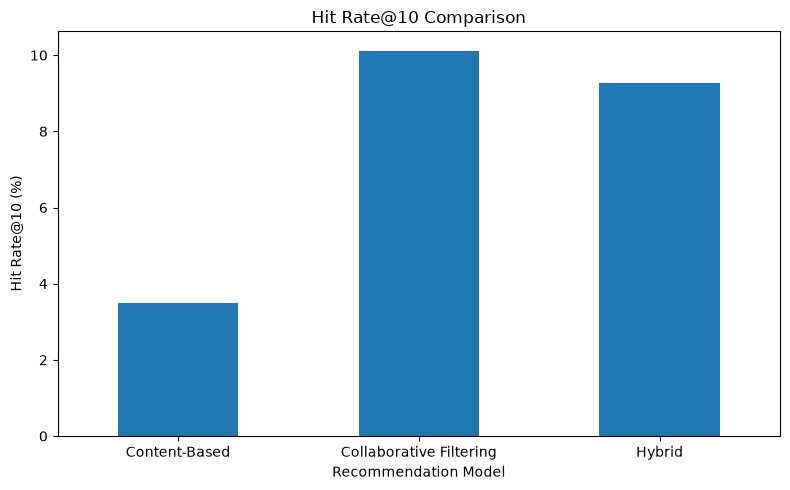

In [92]:
# Visualize Hit Rate@10 across the recommendation models

# Import Matplotlib for evaluation result visualizations
import matplotlib.pyplot as plt
evaluation_results.plot(
    x="Model",
    y="Hit Rate@10 (%)",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Hit Rate@10 Comparison")
plt.ylabel("Hit Rate@10 (%)")
plt.xlabel("Recommendation Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

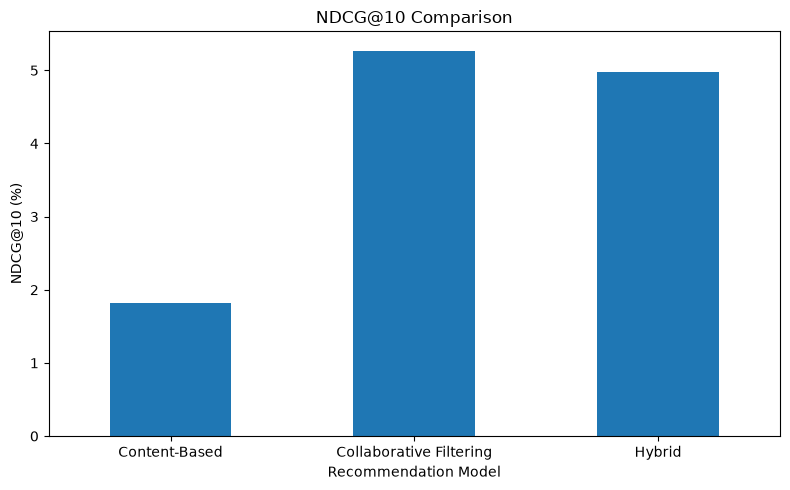

In [93]:
# Visualize NDCG@10 across the recommendation models
evaluation_results.plot(
    x="Model",
    y="NDCG@10 (%)",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("NDCG@10 Comparison")
plt.ylabel("NDCG@10 (%)")
plt.xlabel("Recommendation Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Conclusion

The recommendation models were evaluated using a temporal leave-one-out evaluation protocol. For each evaluated user, the most recent positive rating was held out as the test item, while all model calculations were performed using the remaining training ratings.

The evaluation results were:

* **Content-Based:** Hit Rate@10 = 3.50%, NDCG@10 = 1.82%
* **Collaborative Filtering:** Hit Rate@10 = 10.12%, NDCG@10 = 5.27%
* **Hybrid:** Hit Rate@10 = 9.26%, NDCG@10 = 4.98%

Collaborative filtering achieved the strongest performance across both Hit Rate@10 and NDCG@10. The hybrid recommender performed closely behind collaborative filtering, demonstrating that combining content and behavioral signals can produce competitive recommendations, although the initial hybrid weights did not outperform the collaborative model in this evaluation.

The content-based model showed lower standalone predictive performance under the current evaluation protocol. However, it remains useful as a complementary recommendation signal, particularly for new or less frequently rated movies where behavioral information may be limited.

Overall, the evaluation provides a quantitative basis for selecting and improving the recommendation models used in the final application. The current hybrid weights are treated as initial configuration values rather than optimized parameters.


In [94]:
# Verify that all trained model files required by the application exist
required_files = [
    "tfidf_matrix.npz",
    "tfidf_vectorizer.joblib",
    "collaborative_svd.joblib",
    "user_to_index.joblib",
    "movie_to_index.joblib",
    "user_ids.npy",
    "movie_ids.npy",
    "movie_user_matrix.npz",
    "movie_ids_aw.npy",
    "movie_to_index_aw.joblib",
    "movie_user_counts.csv",
    "hybrid_config.joblib"
]

for filename in required_files:
    file_path = MODELS_DIR / filename
    print(
        filename,
        "→",
        "OK" if file_path.exists() else "MISSING"
    )

tfidf_matrix.npz → OK
tfidf_vectorizer.joblib → OK
collaborative_svd.joblib → OK
user_to_index.joblib → OK
movie_to_index.joblib → OK
user_ids.npy → OK
movie_ids.npy → OK
movie_user_matrix.npz → OK
movie_ids_aw.npy → OK
movie_to_index_aw.joblib → OK
movie_user_counts.csv → OK
hybrid_config.joblib → OK
